In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import numpy as np

In [2]:
df = pd.read_csv('../CSVs/año_tasa.csv')

In [3]:
# x_train es una variable de entrada
# y_train es el objetivo
x_train = df.iloc[0:6,0].values
y_train = df.iloc[0:6,1].values

print(f"x_train: {x_train}")
print(f"y_train: {y_train}")

x_train: [1950 1960 1970 1980 1990 2000]
y_train: [29.3 26.  20.  12.6  9.2  6.9]


In [5]:
# m es el número de ejemplos de entrenamiento
print(f"x_train.shape: {x_train.shape}")
m = x_train.shape[0]
print(f"El número de ejemplos de entrenamiento es: {m}")

x_train.shape: (6,)
El número de ejemplos de entrenamiento es: 6


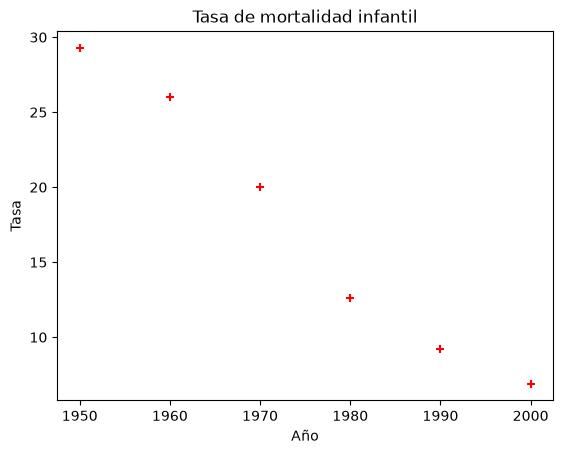

In [6]:
# Graficar los puntos de datos
plt.scatter(x_train, y_train, marker='+', c='r')
plt.title("Tasa de mortalidad infantil")
plt.ylabel('Tasa')
plt.xlabel('Año')
plt.show()

In [7]:
# Valores para w y b
w = -0.48371429
b = 972.652381

print(f"w: {w}")
print(f"b: {b}")

w: -0.48371429
b: 972.652381


In [8]:
def compute_model_output(x, w, b):
    """
    Calcula la predicción de un modelo lineal.

    Args:
        x (ndarray (m,)): Datos, m ejemplos.
        w,b (scalar): Parámetros del modelo.
    Returns:
        f_wb (ndarray (m,)): Predicciones del modelo.
    """
    m = x.shape[0]
    f_wb = np.zeros(m)

    for i in range(m):
        f_wb[i] = w * x[i] + b

    return f_wb

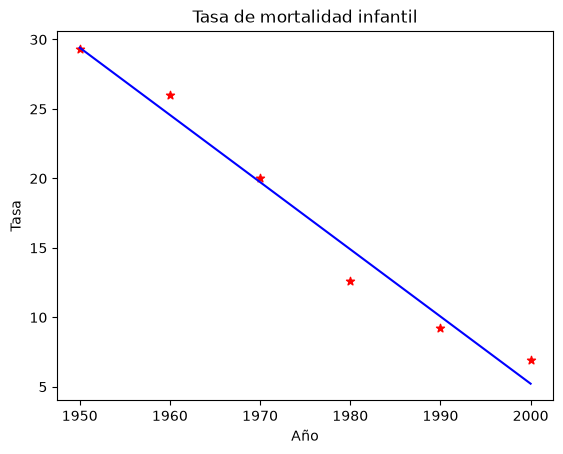

In [9]:
tmp_f_wb = compute_model_output(x_train, w, b)

plt.plot(x_train, tmp_f_wb, c='b', label='Predicción del modelo')
plt.scatter(x_train, y_train, marker='*', c='r', label='Valores reales')
plt.title("Tasa de mortalidad infantil")
plt.ylabel('Tasa')
plt.xlabel('Año')
plt.show()

In [10]:
x_i = 1995

tasaInfantil = w * x_i + b
print(f"{tasaInfantil:.1f} es la tasa de mortalidad infantil para el año {x_i}.")

7.6 es la tasa de mortalidad infantil para el año 1995.


In [11]:
x_i = 2006

tasaInfantil = w * x_i + b
print(f"{tasaInfantil:.1f} es la tasa de mortalidad infantil para el año {x_i}.")

2.3 es la tasa de mortalidad infantil para el año 2006.


In [12]:
def compute_cost(x, y, w, b):
    """
    Calculando la función de costo para la regresión lineal.

    Args:
        x (ndarray (m,)): Datos, m ejemplos.
        y (ndarray (m,)): Valores objetivos.
        w,b (scalar): Parámetros del modelo.
    Returns:
        total_cost (float): El costo de usar w,b como parámeros para la regresión lineal
                            para ajustar los puntos de datos en x y y.
    """
    m = x.shape[0]  # número de ejemplos de entrenamiento
    total_cost = 0
    cost_sum = 0
    for i in range(m):
        f_wb = w * x[i] + b  # Predicción del modelo
        cost = (f_wb - y[i]) ** 2  # Costo para el ejemplo i
        cost_sum += cost  # Suma del costo

    total_cost = ( 1 / (2 * m)) * cost_sum  # Promedio del costo

    return total_cost

In [13]:
result = compute_cost(x_train, y_train, w, b)
print("La medida de precisión es: ",result)

La medida de precisión es:  0.9126906147179629
